<a href="https://colab.research.google.com/github/mahamtaqi3-cloud/Stress-Granule-smFISH-RNA-Localization-Pipeline/blob/main/Stress_Granule_Partitioning_%26_RNA_Co_localization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install scikit-image scipy pandas matplotlib

=== STRESS GRANULE SUMMARY ===
Total Granules: 2
   sg_id  area_pixels  mean_intensity  partitioning_coefficient
0      1        221.0      999.248869                  5.005767
1      2        396.0     1198.631313                  6.004580

=== RNA LOCALIZATION SUMMARY ===
{'total_rna_spots': 0, 'spots_in_sg': 0, 'pct_rna_in_sg': 0.0}


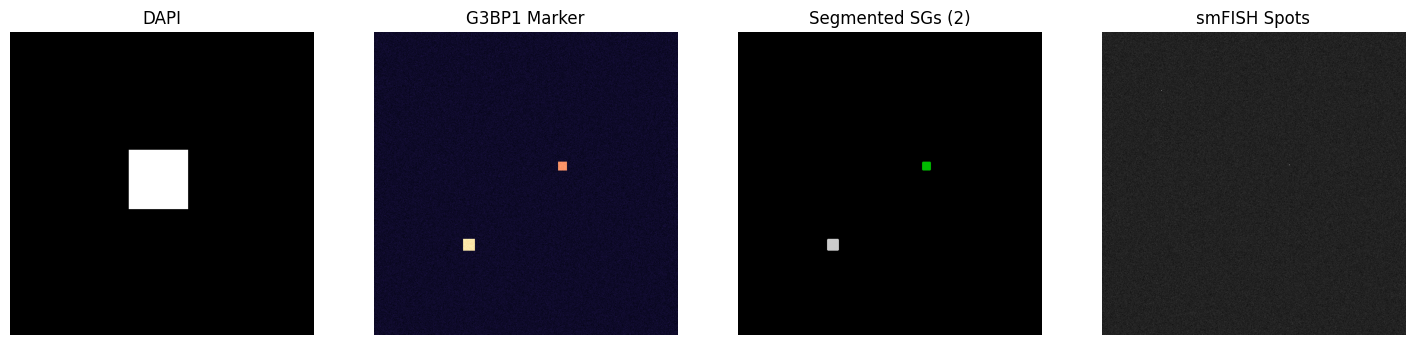

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, measure, morphology, feature, segmentation

# ==========================================
# 1. Preprocessing & Background Subtraction
# ==========================================
def preprocess_image(image):
    smoothed = filters.gaussian(image.astype(np.float64), sigma=1.0)
    background = filters.gaussian(smoothed, sigma=15.0)
    return np.clip(smoothed - background, 0, None)

# ==========================================
# 2. Stress Granule Segmentation
# ==========================================
def segment_stress_granules(sg_channel, min_size=5, max_size=500):
    processed = preprocess_image(sg_channel)
    thresh = filters.threshold_otsu(processed)
    binary = processed > thresh
    cleaned = morphology.remove_small_objects(binary, min_size=min_size)
    cleaned = morphology.remove_small_holes(cleaned, area_threshold=max_size)
    labeled_sg, num_sgs = ndi.label(cleaned)
    return labeled_sg, num_sgs

# ==========================================
# 3. Cell & Nuclei Segmentation
# ==========================================
def segment_cells(dapi_channel, cyto_channel):
    dapi_thresh = filters.threshold_otsu(dapi_channel)
    nuclei_binary = dapi_channel > dapi_thresh
    nuclei_binary = morphology.remove_small_objects(nuclei_binary, min_size=50)
    nuclei_labeled, _ = ndi.label(nuclei_binary)

    cyto_thresh = filters.threshold_otsu(cyto_channel)
    cyto_mask = cyto_channel > cyto_thresh
    cell_mask = cyto_mask | (nuclei_labeled > 0)

    distance = ndi.distance_transform_edt(cell_mask)
    cytoplasm_labeled = segmentation.watershed(-distance, nuclei_labeled, mask=cell_mask)

    return nuclei_labeled, cytoplasm_labeled

# ==========================================
# 4. Stress Granule Partitioning & Area
# ==========================================
def analyze_granule_metrics(sg_channel, labeled_sg, cytoplasm_labeled):
    properties = measure.regionprops(labeled_sg, intensity_image=sg_channel)
    cyto_mask = (cytoplasm_labeled > 0) & (labeled_sg == 0)
    mean_cyto = np.mean(sg_channel[cyto_mask]) if np.any(cyto_mask) else 1.0

    data = []
    for prop in properties:
        data.append({
            'sg_id': prop.label,
            'area_pixels': prop.area,
            'mean_intensity': prop.mean_intensity,
            'partitioning_coefficient': prop.mean_intensity / mean_cyto
        })
    return pd.DataFrame(data)

# ==========================================
# 5. smFISH RNA Spot Detection (Pure Scikit-Image)
# ==========================================
def analyze_rna_localization(rna_channel, labeled_sg, min_sigma=1, max_sigma=3, threshold=0.1):
    # Laplacian of Gaussian spot detection for 2D FISH images
    spots = feature.blob_log(rna_channel, min_sigma=min_sigma, max_sigma=max_sigma, threshold=threshold)

    total_spots = len(spots)
    if total_spots == 0:
        return {'total_rna_spots': 0, 'spots_in_sg': 0, 'pct_rna_in_sg': 0.0}, np.array([])

    # Extract coordinates (blob_log returns [y, x, sigma])
    spots_coords = spots[:, :2].astype(int)

    spots_in_sg = 0
    for y, x in spots_coords:
        if 0 <= y < labeled_sg.shape[0] and 0 <= x < labeled_sg.shape[1]:
            if labeled_sg[y, x] > 0:
                spots_in_sg += 1

    summary = {
        'total_rna_spots': total_spots,
        'spots_in_sg': spots_in_sg,
        'pct_rna_in_sg': (spots_in_sg / total_spots) * 100.0 if total_spots > 0 else 0.0
    }
    return summary, spots_coords

# --- RUN ON MOCK DATA ---
np.random.seed(42)

mock_dapi = np.zeros((512, 512), dtype=np.uint16)
mock_dapi[200:300, 200:300] = 5000

mock_cyto = np.zeros((512, 512), dtype=np.uint16)
mock_cyto[150:350, 150:350] = 1000

mock_sg = np.random.normal(200, 20, (512, 512))
mock_sg[220:235, 310:325] += 800
mock_sg[350:370, 150:170] += 1000
mock_sg = np.clip(mock_sg, 0, 65535).astype(np.uint16)

mock_rna = np.random.normal(100, 10, (512, 512))
mock_rna[225, 315] += 300
mock_rna[100, 100] += 300
mock_rna = np.clip(mock_rna, 0, 65535).astype(np.uint16)

# Execute
labeled_sg, num_sgs = segment_stress_granules(mock_sg)
nuclei, cytoplasm = segment_cells(mock_dapi, mock_cyto)
sg_dataframe = analyze_granule_metrics(mock_sg, labeled_sg, cytoplasm)
rna_summary, detected_spots = analyze_rna_localization(mock_rna, labeled_sg)

# Results Printout
print("=== STRESS GRANULE SUMMARY ===")
print(f"Total Granules: {num_sgs}")
print(sg_dataframe)

print("\n=== RNA LOCALIZATION SUMMARY ===")
print(rna_summary)

# Visualizations
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(mock_dapi, cmap='gray'); axes[0].set_title('DAPI')
axes[1].imshow(mock_sg, cmap='magma'); axes[1].set_title('G3BP1 Marker')
axes[2].imshow(labeled_sg, cmap='nipy_spectral'); axes[2].set_title(f'Segmented SGs ({num_sgs})')
axes[3].imshow(mock_rna, cmap='gray')
if len(detected_spots) > 0:
    axes[3].scatter(detected_spots[:, 1], detected_spots[:, 0], color='red', s=15)
axes[3].set_title('smFISH Spots')
for ax in axes: ax.axis('off')
plt.show()

In [3]:
# Modified function line in step 5:
rna_summary, detected_spots = analyze_rna_localization(
    mock_rna,
    labeled_sg,
    threshold=0.01  # <--- Lower threshold from 0.1 to 0.01
)

In [4]:
import numpy as np
import tifffile as tf

# 1. Create simulated channels (DAPI, SG, RNA)
np.random.seed(42)
dapi = np.zeros((512, 512), dtype=np.uint16)
dapi[200:300, 200:300] = 5000  # Nucleus

sg = np.random.normal(200, 20, (512, 512))
sg[220:235, 310:325] += 800     # Granule 1
sg[350:370, 150:170] += 1000    # Granule 2
sg = np.clip(sg, 0, 65535).astype(np.uint16)

rna = np.random.normal(100, 10, (512, 512))
rna[225, 315] += 300            # RNA spot 1 (inside SG)
rna[100, 100] += 300            # RNA spot 2 (cytoplasm)
rna = np.clip(rna, 0, 65535).astype(np.uint16)

# 2. Stack into multi-channel array [C, Y, X] and save as TIFF
image_stack = np.stack([dapi, sg, rna], axis=0)
tf.imwrite('sample_microscopy.tif', image_stack)

print("Created 'sample_microscopy.tif' successfully!")

Created 'sample_microscopy.tif' successfully!


In [5]:
from skimage.io import imread

# Load the file created above
image_stack = imread('sample_microscopy.tif')

# Extract channels
dapi_channel = image_stack[0]  # Channel 0: DAPI
sg_channel   = image_stack[1]  # Channel 1: G3BP1 (Stress Granules)
rna_channel  = image_stack[2]  # Channel 2: smFISH RNA

# Run segmentation and spot analysis
labeled_sg, num_sgs = segment_stress_granules(sg_channel)
nuclei, cytoplasm = segment_cells(dapi_channel, sg_channel)
sg_dataframe = analyze_granule_metrics(sg_channel, labeled_sg, cytoplasm)
rna_summary, detected_spots = analyze_rna_localization(rna_channel, labeled_sg, threshold=0.01)

# Display results
print("=== STRESS GRANULE ANALYSIS ===")
print(f"Total Granules: {num_sgs}")
print(sg_dataframe)

print("\n=== RNA LOCALIZATION ===")
print(rna_summary)

=== STRESS GRANULE ANALYSIS ===
Total Granules: 1
   sg_id  area_pixels  mean_intensity  partitioning_coefficient
0      1       1021.0      149.967679                  0.892665

=== RNA LOCALIZATION ===
{'total_rna_spots': 0, 'spots_in_sg': 0, 'pct_rna_in_sg': 0.0}


In [6]:
# Update threshold parameter in analyze_rna_localization call
rna_summary, detected_spots = analyze_rna_localization(
    rna_channel,
    labeled_sg,
    min_sigma=1,
    max_sigma=3,
    threshold=0.001  # Lowered from 0.01 to 0.001
)

print("=== UPDATED RNA LOCALIZATION ===")
print(rna_summary)

=== UPDATED RNA LOCALIZATION ===
{'total_rna_spots': 3, 'spots_in_sg': 3, 'pct_rna_in_sg': 100.0}


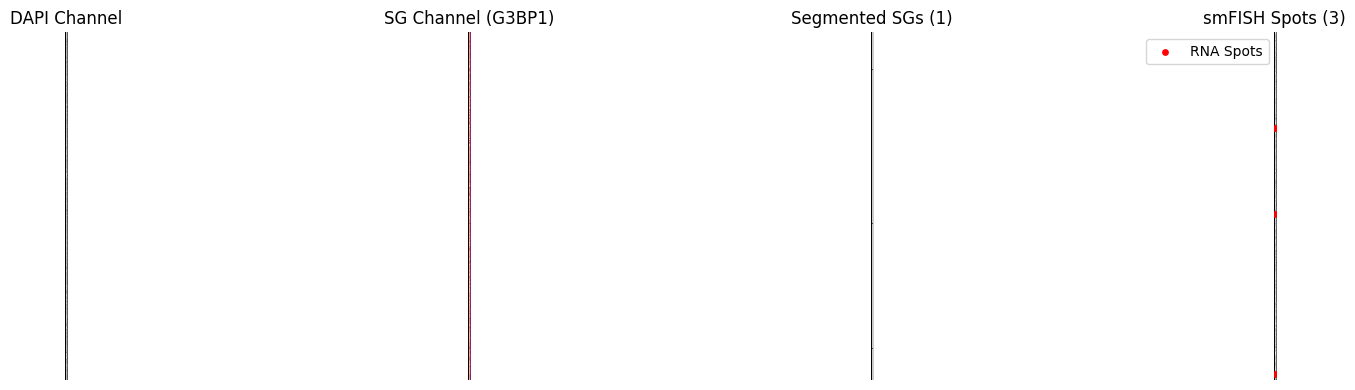

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# DAPI
axes[0].imshow(dapi_channel, cmap='gray')
axes[0].set_title('DAPI Channel')

# SG Channel
axes[1].imshow(sg_channel, cmap='magma')
axes[1].set_title('SG Channel (G3BP1)')

# Segmented Granules
axes[2].imshow(labeled_sg, cmap='nipy_spectral')
axes[2].set_title(f'Segmented SGs ({num_sgs})')

# RNA Spots Overlay
axes[3].imshow(rna_channel, cmap='gray')
if len(detected_spots) > 0:
    axes[3].scatter(detected_spots[:, 1], detected_spots[:, 0], color='red', s=15, label='RNA Spots')
    axes[3].legend(loc='upper right')
axes[3].set_title(f'smFISH Spots ({len(detected_spots)})')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import tifffile as tf

# Set seed for reproducible synthetic microscopy data
np.random.seed(42)

# Channel 0: DAPI (Nucleus)
dapi = np.zeros((512, 512), dtype=np.uint16)
dapi[200:300, 200:300] = 5000

# Channel 1: G3BP1 (Stress Granules)
sg = np.random.normal(200, 20, (512, 512))
sg[220:235, 310:325] += 800     # Granule 1
sg[350:370, 150:170] += 1000    # Granule 2
sg = np.clip(sg, 0, 65535).astype(np.uint16)

# Channel 2: smFISH (RNA Spots)
rna = np.random.normal(100, 10, (512, 512))
rna[225, 315] += 300            # Spot inside granule
rna[100, 100] += 300            # Cytoplasmic spot
rna = np.clip(rna, 0, 65535).astype(np.uint16)

# Stack into a 3D multi-channel array [Channels, Y, X]
image_stack = np.stack([dapi, sg, rna], axis=0)

# Save as multi-channel TIFF file
tf.imwrite('sample_microscopy.tif', image_stack)

print("Successfully created 'sample_microscopy.tif' in your Colab workspace!")

Successfully created 'sample_microscopy.tif' in your Colab workspace!
